In [ ]:
# DS 4002 — Project 3: MI2 Metadata Preparation
# Team: The Pink Panthers — Shawn Chen and Zichen Luo
#
# PURPOSE
# Join DVM-CAR advertisement and image metadata, identify listings with
# front/side/rear coverage, produce MI2 exploratory plots, and select
# a 90-image sample for visual auditing.
#
# INPUTS
# Upload Ad_table (extra).csv and Image_table.csv at the first prompt.
# Source: https://deepvisualmarketing.github.io/
#
# PLATFORM AND PACKAGES
# Google Colab, Python 3, pandas, NumPy, and matplotlib.
#
# EXECUTION
# Run the metadata and export cells in order.
#
# OUTPUTS
# Tables, candidate records, audit template, and plots:
# /content/mi2_outputs/
# Downloadable archive: /content/MI2_Metadata_Results.zip
#
# SCOPE
# These are candidate-data outputs before final visual cleaning.
# This notebook does not create the later 4,500-image review archive
# or the final cleaned dataset and training/validation/test splits.
# Those later stages are documented separately.

In [1]:
from google.colab import files
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile

uploaded = files.upload()

ad_files = [
    name for name in uploaded
    if name.lower().startswith("ad_table") and name.lower().endswith(".csv")
]
image_files = [
    name for name in uploaded
    if name.lower().startswith("image_table") and name.lower().endswith(".csv")
]

assert len(ad_files) == 1, "Upload exactly one Ad_table CSV."
assert len(image_files) == 1, "Upload exactly one Image_table CSV."

ads = pd.read_csv(
    ad_files[0], dtype="string", skipinitialspace=True
)
images = pd.read_csv(
    image_files[0], dtype="string", skipinitialspace=True
)

for frame in [ads, images]:
    frame.columns = frame.columns.str.strip()
    for column in frame.columns:
        frame[column] = frame[column].str.strip().replace("", pd.NA)

required_ad_columns = ["Adv_ID", "Genmodel_ID", "Bodytype"]
required_image_columns = [
    "Genmodel_ID", "Image_ID", "Image_name", "Predicted_viewpoint"
]

assert set(required_ad_columns).issubset(ads.columns)
assert set(required_image_columns).issubset(images.columns)

print(f"Advertisement rows: {len(ads):,}")
print(f"Image metadata rows: {len(images):,}")

print("\nAdvertisement columns")
print(ads.columns.tolist())

print("\nImage metadata columns")
print(images.columns.tolist())

display(ads.head())
display(images.head())

Saving Ad_table (extra).csv to Ad_table (extra).csv
Saving Image_table.csv to Image_table.csv
Advertisement rows: 268,255
Image metadata rows: 1,451,784

Advertisement columns
['Maker', 'Genmodel', 'Genmodel_ID', 'Adv_ID', 'Adv_year', 'Adv_month', 'Color', 'Reg_year', 'Bodytype', 'Runned_Miles', 'Engin_size', 'Gearbox', 'Fuel_type', 'Price', 'Engine_power', 'Annual_Tax', 'Wheelbase', 'Height', 'Width', 'Length', 'Average_mpg', 'Top_speed', 'Seat_num', 'Door_num']

Image metadata columns
['Genmodel_ID', 'Image_ID', 'Image_name', 'Predicted_viewpoint', 'Quality_check']


,Maker,Genmodel,Genmodel_ID,Adv_ID,Adv_year,Adv_month,Color,Reg_year,Bodytype,Runned_Miles,...,Engine_power,Annual_Tax,Wheelbase,Height,Width,Length,Average_mpg,Top_speed,Seat_num,Door_num
0,Bentley,Arnage,10_1,10_1$$1,2018,4,Silver,2000,Saloon,60000,...,<NA>,<NA>,3116,1515,2125,5390,<NA>,<NA>,5,4
1,Bentley,Arnage,10_1,10_1$$2,2018,6,Grey,2002,Saloon,44000,...,450,315,3116,1515,2125,5390,13.7 mpg,179 mph,5,4
2,Bentley,Arnage,10_1,10_1$$3,2017,11,Blue,2002,Saloon,55000,...,400,315,3116,1515,2125,5390,14.7 mpg,155 mph,5,4
3,Bentley,Arnage,10_1,10_1$$4,2018,4,Green,2003,Saloon,14000,...,<NA>,<NA>,3116,1515,2125,5390,<NA>,<NA>,5,4
4,Bentley,Arnage,10_1,10_1$$5,2017,11,Grey,2003,Saloon,61652,...,<NA>,<NA>,3116,1515,2125,5390,<NA>,<NA>,5,4


,Genmodel_ID,Image_ID,Image_name,Predicted_viewpoint,Quality_check
0,2_1,2_1$$1$$1,Abarth$$124 Spider$$2017$$Blue$$2_1$$1$$image_...,45,<NA>
1,2_1,2_1$$10$$11,Abarth$$124 Spider$$2017$$Blue$$2_1$$10$$image...,45,<NA>
2,2_1,2_1$$10$$16,Abarth$$124 Spider$$2017$$Blue$$2_1$$10$$image...,0,N
3,2_1,2_1$$10$$18,Abarth$$124 Spider$$2017$$Blue$$2_1$$10$$image...,270,<NA>
4,2_1,2_1$$10$$2,Abarth$$124 Spider$$2017$$Blue$$2_1$$10$$image...,180,<NA>


In [2]:
output_dir = Path("/content/mi2_outputs")
output_dir.mkdir(exist_ok=True)

missing_ads = pd.DataFrame({
    "missing_count": ads.isna().sum(),
    "missing_percent": ads.isna().mean().mul(100).round(2)
})

missing_images = pd.DataFrame({
    "missing_count": images.isna().sum(),
    "missing_percent": images.isna().mean().mul(100).round(2)
})

print("ADVERTISEMENT MISSING VALUES")
display(missing_ads)

print("IMAGE METADATA MISSING VALUES")
display(missing_images)

duplicate_summary = pd.DataFrame({
    "check": [
        "Exact duplicate advertisement rows",
        "Exact duplicate image metadata rows",
        "Repeated nonmissing advertisement IDs",
        "Repeated nonmissing image IDs",
        "Repeated nonmissing image filenames"
    ],
    "count": [
        ads.duplicated().sum(),
        images.duplicated().sum(),
        ads["Adv_ID"].dropna().duplicated().sum(),
        images["Image_ID"].dropna().duplicated().sum(),
        images["Image_name"].dropna().duplicated().sum()
    ]
})

display(duplicate_summary)

print("BODY-TYPE LABELS")
display(ads["Bodytype"].value_counts(dropna=False).to_frame("rows"))

print("PREDICTED VIEWPOINT CODES")
display(
    images["Predicted_viewpoint"]
    .value_counts(dropna=False)
    .to_frame("rows")
)

if "Quality_check" in images.columns:
    print("QUALITY-CHECK VALUES")
    display(
        images["Quality_check"]
        .value_counts(dropna=False)
        .to_frame("rows")
    )

missing_ads.to_csv(output_dir / "ad_missing_values.csv")
missing_images.to_csv(output_dir / "image_missing_values.csv")
duplicate_summary.to_csv(
    output_dir / "duplicate_summary.csv", index=False
)

ADVERTISEMENT MISSING VALUES


,missing_count,missing_percent
Maker,0,0.00
Genmodel,0,0.00
Genmodel_ID,0,0.00
Adv_ID,0,0.00
Adv_year,0,0.00
Adv_month,0,0.00
Color,21875,8.15
Reg_year,7,0.00
Bodytype,954,0.36
Runned_Miles,1055,0.39


IMAGE METADATA MISSING VALUES


,missing_count,missing_percent
Genmodel_ID,0,0.00
Image_ID,0,0.00
Image_name,0,0.00
Predicted_viewpoint,0,0.00
Quality_check,1364791,94.01


,check,count
0,Exact duplicate advertisement rows,0
1,Exact duplicate image metadata rows,0
2,Repeated nonmissing advertisement IDs,0
3,Repeated nonmissing image IDs,852
4,Repeated nonmissing image filenames,0


BODY-TYPE LABELS


,rows
Bodytype,
Hatchback,103768
SUV,64396
Saloon,22583
MPV,22507
Coupe,17082
Estate,16797
Convertible,13206
Pickup,5268
<NA>,954


PREDICTED VIEWPOINT CODES


,rows
Predicted_viewpoint,
0,240502
180,231846
225,213731
90,195258
315,143128
270,142285
45,139809
135,135978
360,9247


QUALITY-CHECK VALUES


,rows
Quality_check,
<NA>,1364791
P,67184
N,19809


In [3]:
# Prepare the advertisement lookup.
ad_lookup = (
    ads[required_ad_columns]
    .dropna(subset=required_ad_columns)
    .drop_duplicates()
    .copy()
)

# Exclude advertisement IDs associated with conflicting model or body-type labels.
ad_conflicts = (
    ad_lookup.groupby("Adv_ID")[["Genmodel_ID", "Bodytype"]]
    .nunique()
    .gt(1)
    .any(axis=1)
)

conflicting_ad_ids = ad_conflicts[ad_conflicts].index

print(f"Conflicting advertisement IDs excluded: {len(conflicting_ad_ids):,}")

ad_lookup = (
    ad_lookup[
        ~ad_lookup["Adv_ID"].isin(conflicting_ad_ids)
    ]
    .drop_duplicates("Adv_ID")
    .rename(columns={"Genmodel_ID": "Ad_Genmodel_ID"})
)

# Prepare image metadata.
image_columns = required_image_columns.copy()
if "Quality_check" in images.columns:
    image_columns.append("Quality_check")

image_clean = (
    images[image_columns]
    .dropna(subset=required_image_columns)
    .drop_duplicates()
    .copy()
)

image_clean["Predicted_viewpoint"] = pd.to_numeric(
    image_clean["Predicted_viewpoint"], errors="coerce"
)

# An Image_ID has the form modelID$$advertisementNumber$$imageNumber.
valid_id = image_clean["Image_ID"].str.count(r"\$\$").eq(2)
print(f"Malformed image IDs excluded: {(~valid_id).sum():,}")

image_clean = image_clean.loc[valid_id].copy()
image_clean["Adv_ID"] = (
    image_clean["Image_ID"].str.rsplit("$$", n=1).str[0]
)

# Exclude IDs with conflicting filename, model, or viewpoint metadata.
image_conflicts = (
    image_clean.groupby("Image_ID")[
        ["Genmodel_ID", "Image_name", "Predicted_viewpoint"]
    ]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

conflicting_image_ids = image_conflicts[image_conflicts].index
print(f"Conflicting image IDs excluded: {len(conflicting_image_ids):,}")

image_clean = (
    image_clean[
        ~image_clean["Image_ID"].isin(conflicting_image_ids)
    ]
    .drop_duplicates("Image_ID")
)

joined = image_clean.merge(
    ad_lookup,
    on="Adv_ID",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("\nJOIN RESULTS")
display(joined["_merge"].value_counts().to_frame("images"))

joined = joined.loc[joined["_merge"].eq("both")].copy()

model_mismatch = joined["Genmodel_ID"].ne(joined["Ad_Genmodel_ID"])
print(f"Model-ID mismatches excluded: {model_mismatch.sum():,}")

joined = joined.loc[~model_mismatch].drop(
    columns=["Ad_Genmodel_ID", "_merge"]
)

body_map = {
    "Saloon": "Sedan",
    "SUV": "SUV",
    "Pickup": "Pickup"
}

view_map = {
    0: "Front",
    90: "Side",
    270: "Side",
    180: "Rear"
}

joined["Body_type"] = joined["Bodytype"].map(body_map)
joined["View"] = joined["Predicted_viewpoint"].map(view_map)

eligible = joined.dropna(subset=["Body_type", "View"]).copy()

classes = ["Sedan", "SUV", "Pickup"]
views = ["Front", "Side", "Rear"]

print(f"\nEligible image metadata rows: {len(eligible):,}")
print(f"Eligible distinct listings: {eligible['Adv_ID'].nunique():,}")
print(f"Eligible distinct model IDs: {eligible['Genmodel_ID'].nunique():,}")

print(
    "\nThese are metadata-eligible images. "
    "Image quality and viewpoint labels still require visual checking."
)

display(
    eligible[
        ["Adv_ID", "Genmodel_ID", "Body_type",
         "View", "Image_name", "Predicted_viewpoint"]
    ].head()
)

Conflicting advertisement IDs excluded: 0
Malformed image IDs excluded: 0
Conflicting image IDs excluded: 845

JOIN RESULTS


,images
_merge,
both,1446844
left_only,3243
right_only,0


Model-ID mismatches excluded: 0

Eligible image metadata rows: 265,593
Eligible distinct listings: 80,241
Eligible distinct model IDs: 319

These are metadata-eligible images. Image quality and viewpoint labels still require visual checking.


,Adv_ID,Genmodel_ID,Body_type,View,Image_name,Predicted_viewpoint
1781,4_4$$16,4_4,Sedan,Side,Alfa Romeo$$159$$2007$$Black$$4_4$$16$$image_0...,90
1782,4_4$$16,4_4,Sedan,Front,Alfa Romeo$$159$$2007$$Black$$4_4$$16$$image_1...,0
1786,4_4$$16,4_4,Sedan,Side,Alfa Romeo$$159$$2007$$Black$$4_4$$16$$image_5...,90
1787,4_4$$16,4_4,Sedan,Front,Alfa Romeo$$159$$2007$$Black$$4_4$$16$$image_6...,0
1788,4_4$$19,4_4,Sedan,Front,Alfa Romeo$$159$$2007$$Black$$4_4$$19$$image_1...,0


In [4]:
image_counts = (
    eligible.groupby(["Body_type", "View"])
    .size()
    .unstack()
    .reindex(index=classes, columns=views)
    .fillna(0)
    .astype(int)
)

listing_counts = (
    eligible.groupby(["Body_type", "View"])["Adv_ID"]
    .nunique()
    .unstack()
    .reindex(index=classes, columns=views)
    .fillna(0)
    .astype(int)
)

model_counts = (
    eligible.groupby(["Body_type", "View"])["Genmodel_ID"]
    .nunique()
    .unstack()
    .reindex(index=classes, columns=views)
    .fillna(0)
    .astype(int)
)

print("IMAGE COUNTS BY BODY TYPE AND VIEW")
display(image_counts)

print("DISTINCT LISTINGS BY BODY TYPE AND VIEW")
display(listing_counts)

print("DISTINCT MODELS BY BODY TYPE AND VIEW")
display(model_counts)

view_coverage = eligible.groupby("Adv_ID")["View"].nunique()
matched_ids = view_coverage[view_coverage.eq(3)].index

matched = eligible[eligible["Adv_ID"].isin(matched_ids)].copy()

matched_listings = matched[
    ["Adv_ID", "Genmodel_ID", "Body_type"]
].drop_duplicates()

matched_summary = (
    matched_listings.groupby("Body_type")
    .agg(
        listings=("Adv_ID", "nunique"),
        models=("Genmodel_ID", "nunique")
    )
    .reindex(classes)
    .fillna(0)
    .astype(int)
)

print("LISTINGS WITH ALL THREE PREDICTED VIEWS")
display(matched_summary)

# Check whether generic model IDs span more than one body type.
# This helps us assess how to stratify a split grouped by model ID.
model_body_counts = (
    matched_listings.groupby("Genmodel_ID")["Body_type"].nunique()
)
multi_body_ids = model_body_counts[model_body_counts.gt(1)].index

print(
    f"Generic model IDs spanning multiple target body types: "
    f"{len(multi_body_ids):,}"
)

if len(multi_body_ids):
    display(
        matched_listings[
            matched_listings["Genmodel_ID"].isin(multi_body_ids)
        ]
        .groupby("Genmodel_ID")["Body_type"]
        .agg(lambda values: ", ".join(sorted(set(values))))
        .head(15)
        .to_frame("body_types")
    )

print("PICKUP COVERAGE BY MODEL")
pickup_coverage = (
    matched_listings[
        matched_listings["Body_type"].eq("Pickup")
    ]
    .groupby("Genmodel_ID")["Adv_ID"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("matched_listings")
)
display(pickup_coverage)

image_counts.to_csv(output_dir / "image_counts_by_view.csv")
listing_counts.to_csv(output_dir / "listing_counts_by_view.csv")
model_counts.to_csv(output_dir / "model_counts_by_view.csv")
matched_summary.to_csv(output_dir / "matched_listing_summary.csv")
pickup_coverage.to_csv(output_dir / "pickup_model_coverage.csv")

IMAGE COUNTS BY BODY TYPE AND VIEW


View,Front,Side,Rear
Body_type,,,
Sedan,21436,27955,20906
SUV,52925,82458,50964
Pickup,3862,3070,2017


DISTINCT LISTINGS BY BODY TYPE AND VIEW


View,Front,Side,Rear
Body_type,,,
Sedan,15421,16013,15478
SUV,41062,48028,39644
Pickup,3128,2024,1682


DISTINCT MODELS BY BODY TYPE AND VIEW


View,Front,Side,Rear
Body_type,,,
Sedan,131,138,134
SUV,157,162,158
Pickup,19,21,19


... (2 outputs left out)

Generic model IDs spanning multiple target body types: 8


,body_types
Genmodel_ID,
38_2,"Pickup, SUV"
47_2,"Pickup, SUV"
53_7,"SUV, Sedan"
62_13,"Pickup, SUV"
64_20,"Pickup, SUV"
85_2,"Pickup, SUV"
92_19,"Pickup, SUV"
95_1,"Pickup, SUV"


PICKUP COVERAGE BY MODEL


,matched_listings
Genmodel_ID,
62_13,195
64_20,128
92_19,94
38_2,70
29_30,42
95_1,22
59_40,7
38_3,6
85_4,5


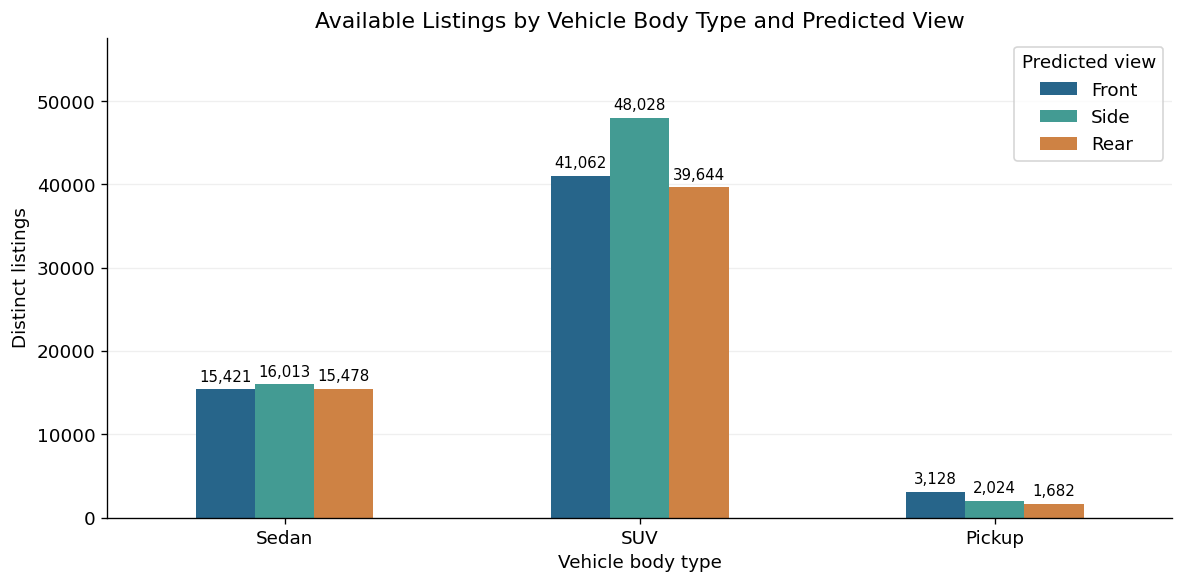

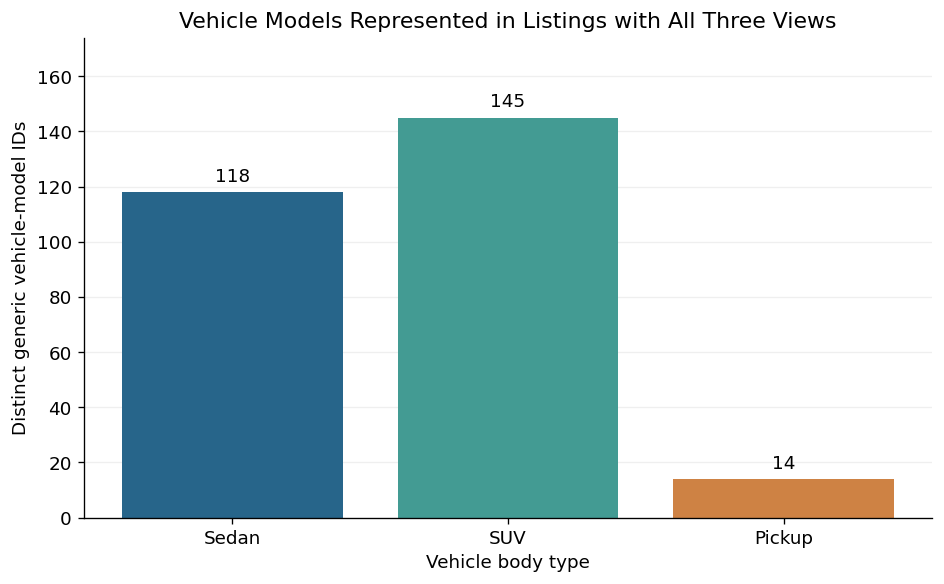

In [5]:
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})

colors = ["#27658A", "#439B93", "#CE8244"]

# Plot 1: Viewpoint coverage.
ax = listing_counts.plot(
    kind="bar",
    figsize=(10, 5),
    color=colors,
    rot=0
)

ax.set_title("Available Listings by Vehicle Body Type and Predicted View")
ax.set_xlabel("Vehicle body type")
ax.set_ylabel("Distinct listings")
ax.legend(title="Predicted view")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)

ax.set_ylim(0, listing_counts.to_numpy().max() * 1.2)
plt.tight_layout()
plt.savefig(
    output_dir / "figure_1_viewpoint_coverage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot 2: Model diversity in the matched-view sample.
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    matched_summary.index,
    matched_summary["models"],
    color=colors
)

ax.set_title("Vehicle Models Represented in Listings with All Three Views")
ax.set_xlabel("Vehicle body type")
ax.set_ylabel("Distinct generic vehicle-model IDs")
ax.bar_label(bars, padding=4)
ax.set_ylim(0, max(1, matched_summary["models"].max()) * 1.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    output_dir / "figure_2_matched_model_coverage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [6]:
SEED = 42

# Select one metadata record per listing and viewpoint.
# This picks a candidate image, not a visually verified image.
selected = (
    matched.sort_values(
        ["Adv_ID", "View", "Image_name", "Image_ID"]
    )
    .drop_duplicates(["Adv_ID", "View"])
    .copy()
)

# Reconstruct the archive path from the filename.
def relative_image_path(filename):
    parts = filename.split("$$")
    if len(parts) < 5:
        return pd.NA
    return "/".join(parts[:4] + [filename])

selected["Relative_path"] = selected["Image_name"].apply(
    relative_image_path
)

assert selected.groupby("Adv_ID")["View"].nunique().eq(3).all()
assert not selected.duplicated(["Adv_ID", "View"]).any()

audit_ids = []

for body_type in classes:
    candidates = (
        matched_listings[
            matched_listings["Body_type"].eq(body_type)
        ]
        .sort_values("Adv_ID")
    )

    sample = candidates.sample(
        n=min(10, len(candidates)),
        random_state=SEED
    )

    audit_ids.extend(sample["Adv_ID"].tolist())

audit = selected[
    selected["Adv_ID"].isin(audit_ids)
].copy()

# Blank fields for the manual review.
audit["Observed_view"] = ""
audit["View_label_correct"] = ""
audit["Body_label_correct"] = ""
audit["Usable"] = ""
audit["Review_notes"] = ""

selected.to_csv(
    output_dir / "candidate_matched_images.csv", index=False
)
audit.to_csv(
    output_dir / "viewpoint_audit_sample.csv", index=False
)

print(f"Candidate matched listings: {selected['Adv_ID'].nunique():,}")
print(f"Candidate selected images: {len(selected):,}")
print(f"Listings selected for initial audit: {audit['Adv_ID'].nunique():,}")
print(f"Images selected for initial audit: {len(audit):,}")

display(
    audit[
        ["Body_type", "Adv_ID", "View", "Image_name", "Relative_path"]
    ].head(12)
)

Candidate matched listings: 40,012
Candidate selected images: 120,036
Listings selected for initial audit: 30
Images selected for initial audit: 90


,Body_type,Adv_ID,View,Image_name,Relative_path
562054,Pickup,38_2$$633,Front,Isuzu$$D-Max$$2017$$Black$$38_2$$633$$image_22...,Isuzu/D-Max/2017/Black/Isuzu$$D-Max$$2017$$Bla...
562055,Pickup,38_2$$633,Rear,Isuzu$$D-Max$$2017$$Black$$38_2$$633$$image_24...,Isuzu/D-Max/2017/Black/Isuzu$$D-Max$$2017$$Bla...
562053,Pickup,38_2$$633,Side,Isuzu$$D-Max$$2017$$Black$$38_2$$633$$image_20...,Isuzu/D-Max/2017/Black/Isuzu$$D-Max$$2017$$Bla...
566321,SUV,39_2$$145,Front,Jaguar$$F-PACE$$2017$$White$$39_2$$145$$image_...,Jaguar/F-PACE/2017/White/Jaguar$$F-PACE$$2017$...
566320,SUV,39_2$$145,Rear,Jaguar$$F-PACE$$2017$$White$$39_2$$145$$image_...,Jaguar/F-PACE/2017/White/Jaguar$$F-PACE$$2017$...
566319,SUV,39_2$$145,Side,Jaguar$$F-PACE$$2017$$White$$39_2$$145$$image_...,Jaguar/F-PACE/2017/White/Jaguar$$F-PACE$$2017$...
580587,Sedan,39_5$$250,Front,Jaguar$$X-Type$$2009$$Black$$39_5$$250$$image_...,Jaguar/X-Type/2009/Black/Jaguar$$X-Type$$2009$...
580594,Sedan,39_5$$250,Rear,Jaguar$$X-Type$$2009$$Black$$39_5$$250$$image_...,Jaguar/X-Type/2009/Black/Jaguar$$X-Type$$2009$...
580591,Sedan,39_5$$250,Side,Jaguar$$X-Type$$2009$$Black$$39_5$$250$$image_...,Jaguar/X-Type/2009/Black/Jaguar$$X-Type$$2009$...
576287,Sedan,39_5$$286,Front,Jaguar$$X-Type$$2005$$Black$$39_5$$286$$image_...,Jaguar/X-Type/2005/Black/Jaguar$$X-Type$$2005$...


In [7]:
archive_path = Path("/content/MI2_Metadata_Results.zip")

with zipfile.ZipFile(
    archive_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file_path in sorted(output_dir.iterdir()):
        if file_path.is_file():
            archive.write(file_path, arcname=file_path.name)

files.download(str(archive_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>